# Interaction plan and feasibility in Vega-Altair

**Data sources:** `data/processed/hotel_bookings_clean.csv` (Part 1) and `country_names.csv` (Part 3), from Antonio, de Almeida and Nunes (2019).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Part 5 (tasks 5.1 and 5.2). This notebook lists every interaction chosen by the students with its trigger, action, reason, keyboard equivalent and course model, and proves that the chart part of each one can be written in Vega-Altair: a small version of each chart is built and compiled to SVG. The final charts are built in Part 6.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration: aggregated tables for the tests](#2.-Initial-exploration:-aggregated-tables-for-the-tests)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: interaction plan](#4.-Analysis:-interaction-plan)
5. [Accessible visualisation: feasibility tests](#5.-Accessible-visualisation:-feasibility-tests)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import pandas as pd
import altair as alt
import vl_convert as vlc

alt.data_transformers.disable_max_rows()
alt.renderers.enable('svg')

CLEAN_FILE = Path('../../data/processed/hotel_bookings_clean.csv')
NAMES_FILE = Path('../../data/processed/country_names.csv')
OUTPUT_DIR = Path('interaction_plan_output')
OUTPUT_DIR.mkdir(exist_ok=True)

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| altair', alt.__version__,
      '| Vega-Lite', alt.SCHEMA_VERSION, '| vl-convert', vlc.__version__)

Python 3.13.18 | pandas 3.0.5 | altair 6.2.2 | Vega-Lite v6.4.1 | vl-convert 1.9.0


## 1. Data loading

In [2]:
# ── Load the cleaned bookings with country names ─────────────────────────────
bookings = pd.read_csv(CLEAN_FILE, keep_default_na=False)
names = pd.read_csv(NAMES_FILE, keep_default_na=False)
bookings = bookings.merge(names[['country', 'country_name']], on='country', how='left')
bookings['arrival_month'] = pd.to_datetime(bookings['arrival_date']).dt.to_period('M').dt.to_timestamp()
print(f'Rows: {len(bookings):,}')

Rows: 119,201


## 2. Initial exploration: aggregated tables for the tests

The raw rows are never charted (architecture.md): the tests use small tables aggregated with pandas, at the level the interactions need (month × hotel, and country × hotel × calendar month), so the filters still work on the columns they need.

In [3]:
# ── Month x hotel: guests of stays, cancellation rate and median price ───────
stays = bookings[bookings['is_canceled'] == 0]
by_month = (bookings.groupby(['arrival_month', 'hotel'])
            .agg(bookings_total=('is_canceled', 'size'), cancelled=('is_canceled', 'sum'))
            .join(stays.groupby(['arrival_month', 'hotel']).agg(guests=('total_guests', 'sum')))
            .join(stays[stays['adr'] > 0].groupby(['arrival_month', 'hotel']).agg(median_price=('adr', 'median')))
            .reset_index())
by_month['cancel_rate'] = 100 * by_month['cancelled'] / by_month['bookings_total']
by_month['year'] = by_month['arrival_month'].dt.year
by_month.head()

,arrival_month,hotel,bookings_total,cancelled,guests,median_price,cancel_rate,year
0,2015-07-01,City Hotel,1396,939,852,80.000,67.263610,2015
1,2015-07-01,Resort Hotel,1377,320,2318,123.000,23.238925,2015
2,2015-08-01,City Hotel,2470,1228,2451,81.000,49.716599,2015
3,2015-08-01,Resort Hotel,1409,366,2344,153.420,25.975869,2015
4,2015-09-01,City Hotel,3524,1542,3456,100.565,43.757094,2015


In [4]:
# ── Country x hotel x calendar month: guests of stays (top 10 countries + Other) ─
top_10 = stays['country_name'].value_counts().head(10).index
stays = stays.assign(country_group=stays['country_name'].where(stays['country_name'].isin(top_10), 'Other'),
                     calendar_month=pd.to_datetime(stays['arrival_date']).dt.month)
by_country_month = (stays.groupby(['country_group', 'hotel', 'calendar_month'])
                    .agg(guests=('total_guests', 'sum')).reset_index())
by_country = by_country_month.groupby(['country_group', 'hotel'], as_index=False)['guests'].sum()
print(f'{len(by_month)} rows month x hotel | {len(by_country_month)} rows country x hotel x month')
print(f"Months on the time axis: {by_month['arrival_month'].nunique()} | country groups on the bar charts: {by_country['country_group'].nunique()}")
by_country.sort_values('guests', ascending=False).head()

52 rows month x hotel | 264 rows country x hotel x month
Months on the time axis: 26 | country groups on the bar charts: 11


,country_group,hotel,guests
15,Portugal,Resort Hotel,18847
14,Portugal,City Hotel,18808
12,Other,City Hotel,18585
2,France,City Hotel,14482
19,United Kingdom,Resort Hotel,11676


## 3. Cleaning and preparation

Nothing is cleaned; the tables above are only for the tests. Part 6 builds the final aggregated tables in `data/processed/`.

## 4. Analysis: interaction plan

Each interaction chosen by the students (task 5.1), with trigger, action, keyboard equivalent, reason and course model (task 5.2: Shneiderman's mantra and the three types of interaction of course 07).

In [5]:
# ── The interaction plan ──────────────────────────────────────────────────────
plan = pd.DataFrame([
    dict(id='I1', name='Hotel filter', screen='Both', type='Manipulation: filter (what to show)', mantra='Zoom and filter',
         trigger='Radio buttons Both / City / Resort', action='KPIs and every chart show only that hotel; the "Showing" line and an aria-live message update',
         keyboard='Tab to the group, arrow keys to change', reason='Natalia compares the city and the resort destination one at a time'),
    dict(id='I2', name='Year filter', screen='Both', type='Manipulation: filter (what to show)', mantra='Zoom and filter',
         trigger='Select All / 2015 (Jul-Dec) / 2016 / 2017 (Jan-Aug)', action='Same as I1 for the chosen year; partial years are named in the label',
         keyboard='Tab, arrow keys, Enter', reason='Monthly report: focus on one season; labels avoid comparing partial years'),
    dict(id='I3', name='Filters kept between screens', screen='Both', type='Exploration: navigation', mantra='Overview first (shared state)',
         trigger='Link to the other screen', action='The link carries the filters (?hotel=...&year=...), so the other screen opens with them',
         keyboard='Tab to the link, Enter', reason='Consistency and less memory load (COGA)'),
    dict(id='I4', name='Reset filters', screen='Both', type='Manipulation: filter', mantra='Zoom and filter (undo)',
         trigger='Reset button, always visible', action='Both hotels and all years; announced',
         keyboard='Tab, Enter or Space', reason='A safe way back (skills: reset always visible)'),
    dict(id='I5', name='Linked month highlight', screen='Main', type='Problem solving: linked views', mantra='Details on demand',
         trigger='Pointer over a month, or arrow keys on the data points of C1, C2 or C3', action='A vertical rule marks the same month in C1, C2 and C3; exact values written in the "Selected point" box',
         keyboard='Arrow keys move the month; Alt + up/down changes hotel', reason='Relate guests, cancellations and price of one month (Q1, Q5, Q7)'),
    dict(id='I6', name='Tooltips', screen='Both', type='Problem solving: details on demand', mantra='Details on demand',
         trigger='Pointer over a mark, or Enter / Space on a focused point', action='Box with the exact formatted value and units',
         keyboard='Enter or Space on a focused point', reason='Exact values without crowding the chart (architecture.md)'),
    dict(id='I7', name='Select a country', screen='Detail', type='Problem solving: linked views', mantra='Details on demand',
         trigger='Click a bar of C4, arrow keys on the bars, or Previous / Next buttons', action='C6, the KPIs, C7, C8 and the map show the selected country; the bar gets an outline and the name and value are written beside the chart; default Portugal',
         keyboard='Arrow keys or Previous / Next (disabled at the ends)', reason='Q3: when each market travels; one country at a time keeps the screen simple'),
    dict(id='I8', name='Show more', screen='Detail', type='Problem solving: overview and detail', mantra='Overview first, details on demand',
         trigger='Button "Show more"', action='Reveals C7, C8 and the map below; button text and aria-expanded change',
         keyboard='Tab, Enter or Space', reason='Keeps at most 3 charts visible (COGA) while Q4 and Q6 stay reachable'),
    dict(id='I9', name='Sort toggle', screen='Detail', type='Manipulation: order (how to show)', mantra='Zoom and filter',
         trigger='Radio buttons "By guests" / "Alphabetical" above C4, C7 and C8', action='The country bars are reordered; the selected country stays selected',
         keyboard='Tab, arrow keys', reason='Find a known country quickly (alphabetical) or see the ranking (by guests)'),
])
print('Interactions:', len(plan), '| every one has trigger, action, keyboard and reason:',
      plan[['trigger', 'action', 'keyboard', 'reason']].ne('').all().all())
plan[['id', 'name', 'screen', 'type', 'mantra']]

Interactions: 9 | every one has trigger, action, keyboard and reason: True


,id,name,screen,type,mantra
0,I1,Hotel filter,Both,Manipulation: filter (what to show),Zoom and filter
1,I2,Year filter,Both,Manipulation: filter (what to show),Zoom and filter
2,I3,Filters kept between screens,Both,Exploration: navigation,Overview first (shared state)
3,I4,Reset filters,Both,Manipulation: filter,Zoom and filter (undo)
4,I5,Linked month highlight,Main,Problem solving: linked views,Details on demand
5,I6,Tooltips,Both,Problem solving: details on demand,Details on demand
6,I7,Select a country,Detail,Problem solving: linked views,Details on demand
7,I8,Show more,Detail,Problem solving: overview and detail,"Overview first, details on demand"
8,I9,Sort toggle,Detail,Manipulation: order (how to show),Zoom and filter


### How the plan follows Shneiderman's mantra

**Overview first:** each screen opens with data already visible (both hotels, whole period; Portugal selected on the detail screen) and its KPIs. **Zoom and filter:** the hotel and year filters (I1, I2), with reset (I4) and the sort toggle (I9). **Details on demand:** tooltips (I6), the linked month (I5), the selected country (I7) and the "Show more" section (I8). Interaction has a cognitive cost (course 07), so there is no zoom, pan or drag: the line and bar charts have at most 26 months or 11 country groups (printed above) and fit the screen, and the map is a small secondary view behind "Show more".

## 5. Accessible visualisation: feasibility tests

Each test builds a small version of the chart with the Altair feature the interaction needs, validates it against the Vega-Lite schema (`to_dict`) and compiles it to SVG with vl-convert (the same engine family as the browser). The keyboard part, the overlay focus ring, aria-live and the link parameters are JavaScript around the charts (wcag-accessibility skill) and are built and tested in Part 6.

In [6]:
# ── Helper: validate and compile a chart, return True if both work ───────────
def compiles(chart):
    spec = chart.to_dict()                       # raises an error if the spec is not valid Vega-Lite
    svg = vlc.vegalite_to_svg(spec)              # raises an error if Vega cannot compile it
    return svg.startswith('<svg')

HOTEL_COLOURS = alt.Scale(domain=['City Hotel', 'Resort Hotel'], range=['#4477AA', '#AA3377'])
HOTEL_DASHES = alt.Scale(domain=['City Hotel', 'Resort Hotel'], range=[[1, 0], [6, 3]])
tests = {}
print('Helper ready')

Helper ready


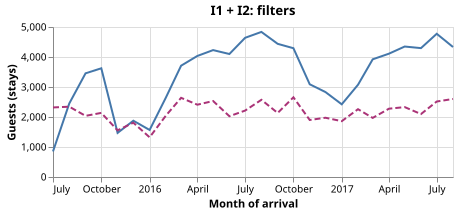

In [7]:
# ── I1 + I2: hotel and year filters as parameters ────────────────────────────
hotel_param = alt.param(name='hotel_filter', value='Both',
                        bind=alt.binding_radio(options=['Both', 'City Hotel', 'Resort Hotel'], name='Hotel: '))
year_param = alt.param(name='year_filter', value=0,
                       bind=alt.binding_select(options=[0, 2015, 2016, 2017],
                                               labels=['All', '2015 (Jul-Dec)', '2016', '2017 (Jan-Aug)'], name='Year: '))

c1_filtered = alt.Chart(by_month).mark_line().encode(
    x=alt.X('arrival_month:T', title='Month of arrival'),
    y=alt.Y('guests:Q', title='Guests (stays)'),
    color=alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=None),
    strokeDash=alt.StrokeDash('hotel:N', scale=HOTEL_DASHES, legend=None),
).add_params(hotel_param, year_param).transform_filter(
    "(hotel_filter == 'Both' || datum.hotel == hotel_filter) && (year_filter == 0 || datum.year == year_filter)"
).properties(title='I1 + I2: filters', width=400, height=150)

tests['I1 Hotel filter'] = tests['I2 Year filter'] = compiles(c1_filtered)
c1_filtered

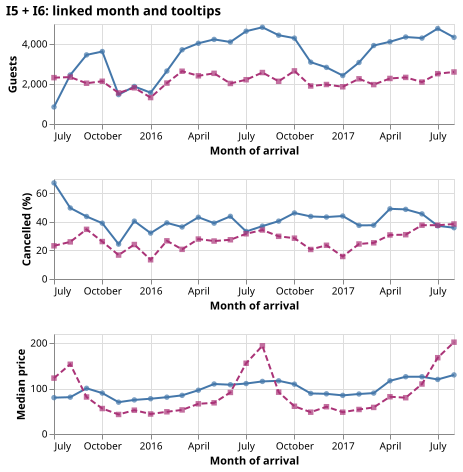

In [8]:
# ── I5 + I6: linked month highlight across C1-C3, with tooltips ──────────────
import warnings
# The same selection is added to the three charts on purpose (that is what links them),
# so Altair's notice that it merged the identical copies is expected and hidden
warnings.filterwarnings('ignore', message='Automatically deduplicated selection parameter')

month_pick = alt.selection_point(name='picked_month', fields=['arrival_month'], on='pointerover',
                                 nearest=True, empty=False)

def month_chart(field, title):
    base = alt.Chart(by_month).encode(x=alt.X('arrival_month:T', title='Month of arrival'))
    lines = base.mark_line().encode(
        y=alt.Y(f'{field}:Q', title=title),
        color=alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=None),
        strokeDash=alt.StrokeDash('hotel:N', scale=HOTEL_DASHES, legend=None))
    points = base.mark_point(filled=True).encode(
        y=f'{field}:Q', color=alt.Color('hotel:N', scale=HOTEL_COLOURS, legend=None),
        shape=alt.Shape('hotel:N', scale=alt.Scale(domain=['City Hotel', 'Resort Hotel'], range=['circle', 'square']), legend=None),
        tooltip=[alt.Tooltip('arrival_month:T', title='Month', format='%B %Y'), alt.Tooltip('hotel:N', title='Hotel'),
                 alt.Tooltip(f'{field}:Q', title=title, format=',.0f')]).add_params(month_pick)
    rule = base.mark_rule(color='#1A1A1A').transform_filter(month_pick)
    return alt.layer(lines, points, rule).properties(width=400, height=100)

linked = alt.vconcat(month_chart('guests', 'Guests'), month_chart('cancel_rate', 'Cancelled (%)'),
                     month_chart('median_price', 'Median price')).properties(title='I5 + I6: linked month and tooltips')
tests['I5 Linked month highlight'] = tests['I6 Tooltips'] = compiles(linked)
linked

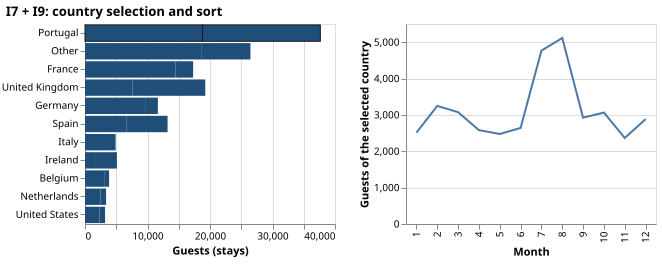

In [9]:
# ── I7 + I9: select a country (drives a second chart) and sort toggle ────────
country_pick = alt.selection_point(name='picked_country', fields=['country_group'], value='Portugal')
sort_param = alt.param(name='sort_order', value='guests',
                       bind=alt.binding_radio(options=['guests', 'alphabetical'], name='Sort: '))

bars = alt.Chart(by_country).transform_calculate(
    # Sort key: number of guests (descending) or the country name, chosen by the toggle
    sort_key="sort_order == 'guests' ? -datum.guests : datum.country_group"
).mark_bar().encode(
    y=alt.Y('country_group:N', title=None, sort=alt.EncodingSortField(field='sort_key', op='min')),
    x=alt.X('guests:Q', title='Guests (stays)'),
    stroke=alt.condition(country_pick, alt.value('#1A1A1A'), alt.value(None)),
    color=alt.value('#1F4E79'),
    tooltip=[alt.Tooltip('country_group:N', title='Country'), alt.Tooltip('guests:Q', title='Guests', format=',.0f')],
).add_params(country_pick, sort_param).properties(width=250, height=200)

season = alt.Chart(by_country_month).transform_filter(country_pick).mark_line().encode(
    x=alt.X('calendar_month:O', title='Month'), y=alt.Y('sum(guests):Q', title='Guests of the selected country'),
).properties(width=250, height=200)

country_link = alt.hconcat(bars, season).properties(title='I7 + I9: country selection and sort')
tests['I7 Select a country'] = tests['I9 Sort toggle'] = compiles(country_link)
country_link

In [10]:
# ── Results of the feasibility tests ─────────────────────────────────────────
html_only = {'I3 Filters kept between screens': 'HTML link with ?hotel=&year= read by JavaScript',
             'I4 Reset filters': 'HTML button that sets the parameters back with view.signal()',
             'I8 Show more': 'HTML button with aria-expanded that shows a hidden section'}
feasibility = pd.DataFrame(
    [(name, 'compiled to SVG' if ok else 'FAILED', 'Vega-Altair parameter / selection') for name, ok in tests.items()]
    + [(name, 'no chart feature needed', how) for name, how in html_only.items()],
    columns=['interaction', 'result', 'how']).sort_values('interaction')
print('All chart tests passed:', all(tests.values()))
feasibility

All chart tests passed: True


,interaction,result,how
0,I1 Hotel filter,compiled to SVG,Vega-Altair parameter / selection
1,I2 Year filter,compiled to SVG,Vega-Altair parameter / selection
6,I3 Filters kept between screens,no chart feature needed,HTML link with ?hotel=&year= read by JavaScript
7,I4 Reset filters,no chart feature needed,HTML button that sets the parameters back with...
2,I5 Linked month highlight,compiled to SVG,Vega-Altair parameter / selection
3,I6 Tooltips,compiled to SVG,Vega-Altair parameter / selection
4,I7 Select a country,compiled to SVG,Vega-Altair parameter / selection
8,I8 Show more,no chart feature needed,HTML button with aria-expanded that shows a hi...
5,I9 Sort toggle,compiled to SVG,Vega-Altair parameter / selection


**Finding:** every chart feature needed by the plan compiles in Vega-Altair 6.2.2 (Vega-Lite 6.4.1): filters bound to parameters, a nearest-point selection shared by three charts with a rule layer, tooltips, a selection that filters another chart, and a sort key computed from a parameter. One limit, said honestly: in the dashboard each chart is embedded separately (each needs its own figure, alternative text and data table), so a selection made in one embed is passed to the others with a few lines of JavaScript (`view.signal()` and `addSignalListener`). This is standard vega-embed use, but it is built and tested only in Part 6.

## 6. Export

In [11]:
# ── Export ────────────────────────────────────────────────────────────────────
plan.to_csv(OUTPUT_DIR / 'interaction_plan.csv', index=False)
feasibility.to_csv(OUTPUT_DIR / 'feasibility_tests.csv', index=False)
sorted(p.name for p in OUTPUT_DIR.iterdir())

['feasibility_tests.csv', 'interaction_plan.csv']

## Conclusions

1. Nine interactions: four of manipulation (hotel and year filters, reset, sort), one of exploration (filters kept between screens) and four of problem solving (linked month, tooltips, country selection, show more).
2. All follow Shneiderman's mantra and each has a keyboard equivalent.
3. Every chart feature compiles in Vega-Altair; linking separate embeds needs a little JavaScript, built in Part 6.